# MADDPG and MAPPO with TorchRL and VMAS

Portfolio packaging for Behrad Mazaheri. Original course/template credits below are retained; individual contributions are unverified.

**Static review only; no cells executed.** Historical outputs are preserved, not independently reproduced. Read README and REVIEW before citing results. Source cell indices in documentation are zero-based before this banner.

Uses TorchRL loss/collector implementations rather than implementing every algorithm from scratch. DDPG budget is 500 × 6000 = 3,000,000 frames; PPO budget is 20 × 6000 = 120,000 frames. Curves therefore do not establish a fair algorithm ranking. TorchRL/TensorDict/VMAS API versions matter; dependency names below are not a compatibility-tested lockfile.



# Multi-Agent Reinforcement Learning (MARL) with TorchRL


In this assignment, you will implement and analyze two foundational algorithms in Multi-Agent Reinforcement Learning (MARL):
- [MADDPG (Multi-Agent Deep Deterministic Policy Gradient)](https://arxiv.org/abs/1706.02275)
- [MAPPO (Multi-Agent Proximal Policy Optimization)](https://arxiv.org/abs/2103.01955)

Both algorithms will be tested in the VMAS (Vectorized Multi-Agent Simulator) navigation environment, where multiple agents must learn to coordinate in a shared space.

In [ ]:
# Cross-platform dependency setup. Xvfb/pyvirtualdisplay are needed only on
# headless Linux machines (for example Colab), not on Windows or macOS.
import platform
import shutil
import subprocess
import sys

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "torchrl",
    "vmas",
    "tqdm",
    "pillow",
])

if platform.system() == "Linux" and shutil.which("apt-get"):
    try:
        subprocess.run(["apt-get", "update", "-y"], check=True)
        subprocess.run(
            [
                "apt-get",
                "install",
                "-y",
                "x11-utils",
                "xvfb",
                "python3-opengl",
                "libgl1-mesa-glx",
                "libglu1-mesa",
            ],
            check=True,
        )
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "pyvirtualdisplay"]
        )
    except (PermissionError, subprocess.CalledProcessError) as error:
        print(f"Optional headless-rendering setup was skipped: {error}")
else:
    print("Xvfb setup skipped: it is only required on headless Linux.")


In [3]:
# Torch
import torch

# Tensordict modules
from tensordict import TensorDictBase
from tensordict.nn import set_composite_lp_aggregate, TensorDictModule, TensorDictSequential
from tensordict.nn.distributions import NormalParamExtractor
from torch import multiprocessing

# Data collection
from torchrl.collectors import Collector
from torchrl.data.replay_buffers import LazyMemmapStorage, RandomSampler, ReplayBuffer
from torchrl.data.replay_buffers.samplers import SamplerWithoutReplacement
from torchrl.data.replay_buffers.storages import LazyTensorStorage

# Env
from torchrl.envs import RewardSum, TransformedEnv
from torchrl.envs.libs.vmas import VmasEnv
from torchrl.envs.utils import check_env_specs

# Multi-agent network
from torchrl.modules import MultiAgentMLP, ProbabilisticActor, AdditiveGaussianModule, TanhNormal, TanhDelta

# Loss
from torchrl.objectives import ClipPPOLoss, DDPGLoss, SoftUpdate, ValueEstimators

# Utils
torch.manual_seed(0)
from matplotlib import pyplot as plt
from tqdm import tqdm
import copy
import tempfile
from matplotlib import pyplot as plt


## Hyperparameters



In [4]:
# Devices
is_fork = multiprocessing.get_start_method() == "fork"
device = (
    torch.device(0)
    if torch.cuda.is_available() and not is_fork
    else torch.device("cpu")
)
vmas_device = device  # The device where the simulator is run (VMAS can run on GPU)

# Sampling
frames_per_batch = 6_000
n_iters = 500  # Number of training iterations
total_frames = frames_per_batch * n_iters

# Training
num_epochs = 30  # Number of optimization steps per training iteration
minibatch_size = 400  # Size of the mini-batches in each optimization step
lr = 3e-4
max_grad_norm = 1.0  # Maximum norm for the gradients

gamma = 0.99  # discount factor

# DDPG Algorithm
polyak_tau = 0.005
memory_size=1_000_000

# PPO
clip_epsilon = 0.2  # clip value for PPO loss
lmbda = 0.9  # lambda for generalised advantage estimation
entropy_eps = 1e-4  # coefficient of the entropy term in the PPO loss

# disable log-prob aggregation
set_composite_lp_aggregate(False).set()

## Environment

We use the VMAS Navigation environment, a vectorized multi-agent simulator.
It runs many environments in parallel on the GPU, where each agent:
- observes its local state
- selects continuous actions
- receives individual rewards



In [5]:
max_steps = 100
num_vmas_envs = (
    frames_per_batch // max_steps
)
scenario_name = "navigation"
n_agents = 3

env = VmasEnv(
    scenario=scenario_name,
    num_envs=num_vmas_envs,
    continuous_actions=True,
    max_steps=max_steps,
    device=vmas_device,
    n_agents=n_agents,
)

In [6]:
print("action_spec:", env.full_action_spec)
print("reward_spec:", env.full_reward_spec)
print("done_spec:", env.full_done_spec)
print("observation_spec:", env.observation_spec)

action_spec: Composite(
    agents: Composite(
        action: BoundedContinuous(
            shape=torch.Size([60, 3, 2]),
            space=ContinuousBox(
                low=Tensor(shape=torch.Size([60, 3, 2]), device=cuda:0, dtype=torch.float32, contiguous=True),
                high=Tensor(shape=torch.Size([60, 3, 2]), device=cuda:0, dtype=torch.float32, contiguous=True)),
            device=cuda:0,
            dtype=torch.float32,
            domain=continuous),
        device=cuda:0,
        shape=torch.Size([60, 3]),
        data_cls=None),
    device=cuda:0,
    shape=torch.Size([60]),
    data_cls=None)
reward_spec: Composite(
    agents: Composite(
        reward: UnboundedContinuous(
            shape=torch.Size([60, 3, 1]),
            space=ContinuousBox(
                low=Tensor(shape=torch.Size([60, 3, 1]), device=cuda:0, dtype=torch.float32, contiguous=True),
                high=Tensor(shape=torch.Size([60, 3, 1]), device=cuda:0, dtype=torch.float32, contiguous=True

In [7]:
print("action_keys:", env.action_keys)
print("reward_keys:", env.reward_keys)
print("done_keys:", env.done_keys)

action_keys: [('agents', 'action')]
reward_keys: [('agents', 'reward')]
done_keys: ['done', 'terminated']


In [8]:
env = TransformedEnv(
    env,
    RewardSum(in_keys=[env.reward_key], out_keys=[("agents", "episode_reward")]),
)

In [9]:
check_env_specs(env)

2026-08-15 13:36:26,540 [torchrl][INFO]    check_env_specs succeeded! [END]


In [10]:
n_rollout_steps = 5
rollout = env.rollout(n_rollout_steps)
print("rollout of three steps:", rollout)
print("Shape of the rollout TensorDict:", rollout.batch_size)

rollout of three steps: TensorDict(
    fields={
        agents: TensorDict(
            fields={
                action: Tensor(shape=torch.Size([60, 5, 3, 2]), device=cuda:0, dtype=torch.float32, is_shared=True),
                episode_reward: Tensor(shape=torch.Size([60, 5, 3, 1]), device=cuda:0, dtype=torch.float32, is_shared=True),
                info: TensorDict(
                    fields={
                        agent_collisions: Tensor(shape=torch.Size([60, 5, 3, 1]), device=cuda:0, dtype=torch.float32, is_shared=True),
                        final_rew: Tensor(shape=torch.Size([60, 5, 3, 1]), device=cuda:0, dtype=torch.float32, is_shared=True),
                        pos_rew: Tensor(shape=torch.Size([60, 5, 3, 1]), device=cuda:0, dtype=torch.float32, is_shared=True)},
                    batch_size=torch.Size([60, 5, 3]),
                    device=cuda:0,
                    is_shared=True),
                observation: Tensor(shape=torch.Size([60, 5, 3, 18]), device=cud

# MADDPG

## Policy

In MADDPG, each agent learns a **deterministic policy** that maps its local observation directly to a continuous action. This actor is implemented as a shared MLP across agents, which promotes parameter sharing and improves sample efficiency by allowing agents to benefit from each other’s experience. Since actions must lie within bounded ranges, the raw network outputs are passed through a `tanh`-based transformation (e.g., `TanhDelta`) to ensure they stay within the valid action space.

Because the policy is deterministic, exploration is not inherent in the network and is instead introduced by adding Gaussian noise to the actions during training. This follows the MADDPG idea of combining stable deterministic policies with explicit exploration noise, enabling agents to explore the environment while still learning a smooth continuous control policy.

In [11]:
share_parameters_policy = True

policy_net = MultiAgentMLP(
    n_agent_inputs=env.observation_spec["agents", "observation"].shape[
        -1
    ],  # n_obs_per_agent
    n_agent_outputs=env.full_action_spec["agents", "action"].shape[
        -1
    ],  # n_actions_per_agents
    n_agents=n_agents,
    centralised=False,  # the policies are decentralised
    share_params=share_parameters_policy,
    device=device,
    depth=2,
    num_cells=256,
    activation_class=torch.nn.Tanh,
)

c:\Users\psp\AppData\Local\Programs\Python\Python312\Lib\site-packages\tensordict\_td.py:612: FutureWarning: TensorDict.to_module() is replacing an existing nn.Parameter in the destination module with a tensor leaf that is not an nn.Parameter. This historical behavior can remove the key from module.state_dict(). In tensordict v0.14, to_module() will preserve existing module parameter and buffer registrations by default. Pass preserve_module_state=False to keep the current replacement behavior, or preserve_module_state=True to opt in to the v0.14 behavior now.
  local_out = _set_tensor_dict(


In [12]:
policy_module = TensorDictModule(
    policy_net,
    in_keys=[("agents", "observation")],
    out_keys=[("agents", "param")],
)

In [13]:
# Deterministic bounded MADDPG actor.
policy = ProbabilisticActor(
    module=policy_module,
    spec=env.full_action_spec["agents", "action"],
    in_keys=[("agents", "param")],
    out_keys=[("agents", "action")],
    distribution_class=TanhDelta,
    distribution_kwargs={
        "low": env.full_action_spec_unbatched["agents", "action"].space.low,
        "high": env.full_action_spec_unbatched["agents", "action"].space.high,
    },
    return_log_prob=False,
)

In [14]:
exploration_policy = TensorDictSequential(
        policy,
        AdditiveGaussianModule(
            spec=policy.spec,
            annealing_num_steps=total_frames
            // 2,  # Number of frames after which sigma is sigma_end
            action_key=env.action_key,
            sigma_init=0.5,  # Initial value of the sigma
            sigma_end=0.5,  # Final value of the sigma
        ),
)

## Critic network
In MADDPG, the critic is **centralized during training**, meaning it receives the concatenated observations and actions of all agents. This allows it to estimate a joint action-value function \( Q(s, a_1, ..., a_n) \), capturing interactions between agents that are not visible locally.

This centralized design improves training stability by reducing non-stationarity, while agents still execute policies **decentrally using only local observations**, following the CTDE paradigm.

In [15]:
share_parameters_critic = True
MADDPG = True  # IDDPG if False

# Join each agent's local observation and action before passing the result to
# MultiAgentMLP. With centralised=True, MultiAgentMLP then concatenates across
# agents internally and returns one centralized Q estimate per agent.
cat_module = TensorDictModule(
    module=lambda obs, action: torch.cat([obs, action], dim=-1),
    in_keys=[("agents", "observation"), ("agents", "action")],
    out_keys=[("agents", "obs_action")],
)

critic_module = TensorDictModule(
    module=MultiAgentMLP(
        n_agent_inputs=env.observation_spec["agents", "observation"].shape[-1]
        + env.full_action_spec["agents", "action"].shape[-1],
        n_agent_outputs=1,
        n_agents=n_agents,
        centralised=MADDPG,
        share_params=share_parameters_critic,
        device=device,
        depth=2,
        num_cells=256,
        activation_class=torch.nn.Tanh,
    ),
    in_keys=[("agents", "obs_action")],
    out_keys=[("agents", "state_action_value")],
)

critic = TensorDictSequential(cat_module, critic_module)

## Data collector

In [ ]:
collector = Collector(
    env,
    exploration_policy,
    device=device,
    frames_per_batch=frames_per_batch,
    total_frames=total_frames,
    auto_register_policy_transforms=True,
)

## Replay buffer

In [17]:
# Keep the TemporaryDirectory object alive for as long as the replay buffer is
# used. Keeping only `.name` would allow Python to delete the directory early.
scratch_dir_handle = tempfile.TemporaryDirectory()
scratch_dir = scratch_dir_handle.name
replay_buffer = ReplayBuffer(
    storage=LazyMemmapStorage(
        memory_size,
        scratch_dir=scratch_dir,
    ),
    sampler=RandomSampler(),
    batch_size=minibatch_size,
)
if device.type != "cpu":
    replay_buffer.append_transform(lambda x: x.to(device))

## Loss function

The DDPG loss consists of:
- Actor loss: improves policy using critic feedback
- Critic loss: fits Q-values using TD targets

Target networks and soft updates stabilize training.

In [18]:
loss_module = DDPGLoss(
    actor_network=policy,  # Use the non-explorative policies
    value_network=critic,
    delay_value=True,  # Whether to use a target network for the value
    loss_function="l2",
)
loss_module.set_keys(
    state_action_value=("agents", "state_action_value"),
    reward=("agents", "reward"),
    done=("agents", "done"),
    terminated=("agents", "terminated"),
)
loss_module.make_value_estimator(ValueEstimators.TD0, gamma=gamma)

In [19]:
target_updater = SoftUpdate(loss_module, tau=polyak_tau)

In [20]:
optimisers = {
        "loss_actor": torch.optim.Adam(
            loss_module.actor_network_params.flatten_keys().values(), lr=lr
        ),
        "loss_value": torch.optim.Adam(
            loss_module.value_network_params.flatten_keys().values(), lr=lr
        ),
    }

## Training Loop

In [21]:
reward_key = env.reward_key
done_key = ("next", "done")
terminated_key = ("next", "terminated")

pbar = tqdm(total=n_iters, desc="Training MADDPG...")
episode_reward_mean_list = []

for tensordict_data in collector:
    reward_shape = tensordict_data.get_item_shape(("next", reward_key))

    tensordict_data.set(
        ("next", "agents", "done"),
        tensordict_data.get(done_key).unsqueeze(-1).expand(reward_shape),
    )
    tensordict_data.set(
        ("next", "agents", "terminated"),
        tensordict_data.get(terminated_key).unsqueeze(-1).expand(reward_shape),
    )

    # MADDPG is off-policy: retain transitions and sample random minibatches.
    replay_buffer.extend(tensordict_data.reshape(-1))

    if len(replay_buffer) >= minibatch_size:
        for _ in range(num_epochs):
            subdata = replay_buffer.sample()
            loss_vals = loss_module(subdata)
            total_loss = loss_vals["loss_actor"] + loss_vals["loss_value"]

            for optimiser in optimisers.values():
                optimiser.zero_grad(set_to_none=True)
            total_loss.backward()

            # Clip exactly the trainable parameters owned by each optimiser.
            for optimiser in optimisers.values():
                params = [
                    parameter
                    for group in optimiser.param_groups
                    for parameter in group["params"]
                ]
                torch.nn.utils.clip_grad_norm_(params, max_grad_norm)
                optimiser.step()
                optimiser.zero_grad(set_to_none=True)

            target_updater.step()

    exploration_policy[-1].step(tensordict_data.numel())

    done = tensordict_data.get(("next", "agents", "done"))
    if done.any():
        episode_reward_mean = (
            tensordict_data.get(("next", "agents", "episode_reward"))[done]
            .mean()
            .item()
        )
        episode_reward_mean_list.append(episode_reward_mean)
        pbar.set_description(
            f"episode_reward_mean = {episode_reward_mean:.2f}", refresh=False
        )

    pbar.update()

pbar.close()

Training MADDPG...:   0%|          | 0/500 [00:00<?, ?it/s]

2026-08-15 13:36:28,421 [torchrl][INFO]    Initialized LazyMemmapStorage with torch.Size([1000000]) shape [END]


episode_reward_mean = 2.63: 100%|██████████| 500/500 [17:47<00:00,  2.14s/it] 


## Results

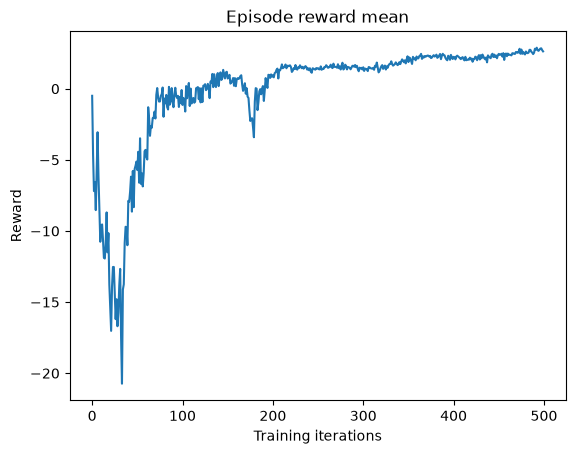

In [22]:
plt.plot(episode_reward_mean_list)
plt.xlabel("Training iterations")
plt.ylabel("Reward")
plt.title("Episode reward mean")
plt.show()

## Render

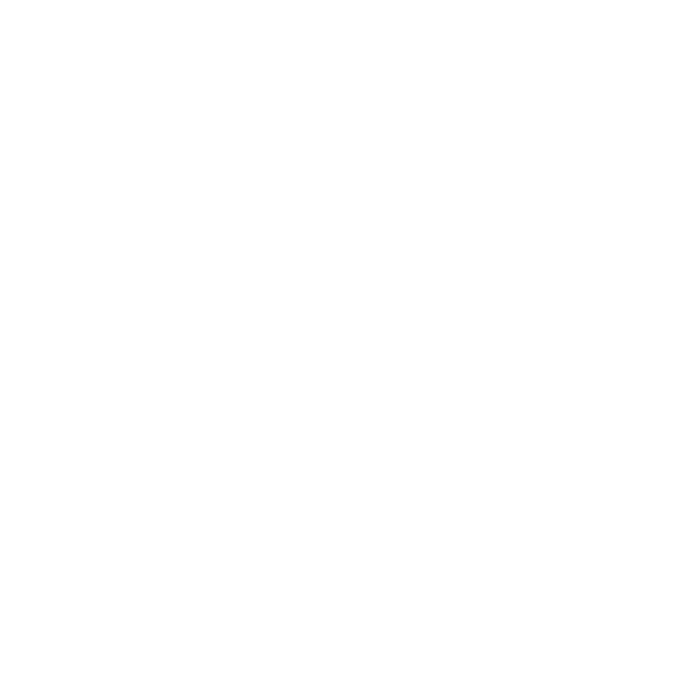

In [23]:
# import pyvirtualdisplay
# display = pyvirtualdisplay.Display(visible=False, size=(1400, 900))
# display.start()
# from PIL import Image

# def rendering_callback(env, td):
#     env.frames.append(Image.fromarray(env.render(mode="rgb_array")))
# env.frames = []
# with torch.no_grad():
#    env.rollout(
#        max_steps=max_steps,
#        policy=policy,
#        callback=rendering_callback,
#        auto_cast_to_device=True,
#        break_when_any_done=False,
#    )
# env.frames[0].save(
#     f"{scenario_name}.gif",
#     save_all=True,
#     append_images=env.frames[1:],
#    duration=3,
#    loop=0,
# )

# from IPython.display import Image
# Image(open(f"{scenario_name}.gif", "rb").read())
from PIL import Image as PILImage
from IPython.display import Image as NotebookImage, display

def rendering_callback(env, td):
    frame = env.render(
        mode="rgb_array",
        visualize_when_rgb=False,
    )
    env.frames.append(PILImage.fromarray(frame))

env.frames = []

with torch.no_grad():
    env.rollout(
        max_steps=max_steps,
        policy=policy,
        callback=rendering_callback,
        auto_cast_to_device=True,
        break_when_any_done=False,
    )

gif_path = f"maddpg_{scenario_name}.gif"

env.frames[0].save(
    gif_path,
    save_all=True,
    append_images=env.frames[1:],
    duration=30,
    loop=0,
)

display(NotebookImage(filename=gif_path))

# MAPPO

## Hyperparameters


In [24]:
frames_per_batch = 6_000
n_iters = 20
total_frames = frames_per_batch * n_iters

## Environment

In [25]:
max_steps = 100
num_vmas_envs = frames_per_batch // max_steps
scenario_name = "navigation"
n_agents = 3

env = VmasEnv(
    scenario=scenario_name,
    num_envs=num_vmas_envs,
    continuous_actions=True,
    max_steps=max_steps,
    device=vmas_device,
    n_agents=n_agents,
)

In [26]:
env = TransformedEnv(
    env,
    RewardSum(in_keys=[env.reward_key], out_keys=[("agents", "episode_reward")]),
)

## Policy
In MAPPO, the policy is stochastic and outputs the parameters of a Gaussian distribution (mean and standard deviation), from which actions are sampled using a squashed distribution like TanhNormal to ensure valid action bounds.

In [27]:
share_parameters_policy = True

policy_net = torch.nn.Sequential(
    MultiAgentMLP(
        n_agent_inputs=env.observation_spec["agents", "observation"].shape[
            -1
        ],  # n_obs_per_agent
        n_agent_outputs=2
        * env.full_action_spec[env.action_key].shape[-1],  # 2 * n_actions_per_agents
        n_agents=env.n_agents,
        centralised=False,  # the policies are decentralised
        share_params=share_parameters_policy,
        device=device,
        depth=2,
        num_cells=256,
        activation_class=torch.nn.Tanh,
    ),
    NormalParamExtractor(),  # this will just separate the last dimension into two outputs: a loc and a non-negative scale
)

In [28]:
policy_module = TensorDictModule(
    policy_net,
    in_keys=[("agents", "observation")],
    out_keys=[("agents", "loc"), ("agents", "scale")],
)

In [29]:
# Stochastic bounded MAPPO actor. The collector stores action_log_prob, which
# ClipPPOLoss later uses to form the new-policy / behavior-policy ratio.
policy = ProbabilisticActor(
    module=policy_module,
    spec=env.action_spec_unbatched,
    in_keys=[("agents", "loc"), ("agents", "scale")],
    out_keys=[env.action_key],
    distribution_class=TanhNormal,
    distribution_kwargs={
        "low": env.full_action_spec_unbatched[env.action_key].space.low,
        "high": env.full_action_spec_unbatched[env.action_key].space.high,
    },
    return_log_prob=True,
)

## Critic network
In MAPPO, the critic estimates the state-value function for each agent using centralized observations. It is used to compute advantage estimates via GAE (Generalized Advantage Estimation), which helps reduce variance and stabilize policy updates during PPO training.


In [30]:
share_parameters_critic = True
mappo = True  # IPPO if False

critic_net = MultiAgentMLP(
    n_agent_inputs=env.observation_spec["agents", "observation"].shape[-1],
    n_agent_outputs=1,  # 1 value per agent
    n_agents=env.n_agents,
    centralised=mappo,
    share_params=share_parameters_critic,
    device=device,
    depth=2,
    num_cells=256,
    activation_class=torch.nn.Tanh,
)

critic = TensorDictModule(
    module=critic_net,
    in_keys=[("agents", "observation")],
    out_keys=[("agents", "state_value")],
)

In [31]:
print("Running policy:", policy(env.reset()))
print("Running value:", critic(env.reset()))

Running policy: TensorDict(
    fields={
        agents: TensorDict(
            fields={
                action: Tensor(shape=torch.Size([60, 3, 2]), device=cuda:0, dtype=torch.float32, is_shared=True),
                action_log_prob: Tensor(shape=torch.Size([60, 3]), device=cuda:0, dtype=torch.float32, is_shared=True),
                episode_reward: Tensor(shape=torch.Size([60, 3, 1]), device=cuda:0, dtype=torch.float32, is_shared=True),
                info: TensorDict(
                    fields={
                        agent_collisions: Tensor(shape=torch.Size([60, 3, 1]), device=cuda:0, dtype=torch.float32, is_shared=True),
                        final_rew: Tensor(shape=torch.Size([60, 3, 1]), device=cuda:0, dtype=torch.float32, is_shared=True),
                        pos_rew: Tensor(shape=torch.Size([60, 3, 1]), device=cuda:0, dtype=torch.float32, is_shared=True)},
                    batch_size=torch.Size([60, 3]),
                    device=cuda:0,
                    is_

## Data collector




In [ ]:
collector = Collector(
    env,
    policy,
    device=vmas_device,
    storing_device=device,
    frames_per_batch=frames_per_batch,
    total_frames=total_frames,
    auto_register_policy_transforms=True,
)

## Replay buffer



In [33]:
replay_buffer = ReplayBuffer(
    storage=LazyTensorStorage(
        frames_per_batch, device=device
    ),  # store the frames_per_batch collected at each iteration
    sampler=SamplerWithoutReplacement(),
    batch_size=minibatch_size,  # sample minibatches of this size
)

## Loss function

PPO optimizes a clipped objective composed of:
- policy loss (improves actions while staying close to old policy)
- value loss (critic accuracy)
- entropy bonus (encourages exploration)

Advantage normalization is disabled across agents to preserve multi-agent structure.



In [34]:
loss_module = ClipPPOLoss(
    actor_network=policy,
    critic_network=critic,
    clip_epsilon=clip_epsilon,
    entropy_coeff=entropy_eps,
    normalize_advantage=False,
)

loss_module.set_keys(
    reward=env.reward_key,
    action=env.action_key,
    value=("agents", "state_value"),
    done=("agents", "done"),
    terminated=("agents", "terminated"),
)

loss_module.make_value_estimator(
    ValueEstimators.GAE, gamma=gamma, lmbda=lmbda
)
GAE = loss_module.value_estimator

optim = torch.optim.Adam(loss_module.parameters(), lr)

## Training loop






In [35]:
pbar = tqdm(total=n_iters, desc="episode_reward_mean = 0")

episode_reward_mean_list = []
for tensordict_data in collector:
    reward_shape = tensordict_data.get_item_shape(("next", env.reward_key))
    tensordict_data.set(
        ("next", "agents", "done"),
        tensordict_data.get(("next", "done")).unsqueeze(-1).expand(reward_shape),
    )
    tensordict_data.set(
        ("next", "agents", "terminated"),
        tensordict_data.get(("next", "terminated"))
        .unsqueeze(-1)
        .expand(reward_shape),
    )

    # Compute fixed GAE/value targets once from the on-policy rollout.
    with torch.no_grad():
        GAE(
            tensordict_data,
            params=loss_module.critic_network_params,
            target_params=loss_module.target_critic_network_params,
        )

    replay_buffer.extend(tensordict_data.reshape(-1))

    for _ in range(num_epochs):
        for _ in range(frames_per_batch // minibatch_size):
            subdata = replay_buffer.sample()
            loss_vals = loss_module(subdata)
            total_loss = (
                loss_vals["loss_objective"]
                + loss_vals["loss_critic"]
                + loss_vals["loss_entropy"]
            )

            optim.zero_grad(set_to_none=True)
            total_loss.backward()
            torch.nn.utils.clip_grad_norm_(loss_module.parameters(), max_grad_norm)
            optim.step()
            optim.zero_grad(set_to_none=True)

    collector.update_policy_weights_()

    done = tensordict_data.get(("next", "agents", "done"))
    if done.any():
        episode_reward_mean = (
            tensordict_data.get(("next", "agents", "episode_reward"))[done]
            .mean()
            .item()
        )
        episode_reward_mean_list.append(episode_reward_mean)
        pbar.set_description(
            f"episode_reward_mean = {episode_reward_mean:.3f}", refresh=False
        )
    pbar.update()

pbar.close()

episode_reward_mean = 0:   0%|          | 0/20 [00:00<?, ?it/s]

2026-08-15 13:54:26,373 [torchrl][INFO]    Initialized LazyTensorStorage with torch.Size([6000]) shape [END]


episode_reward_mean = 3.198: 100%|██████████| 20/20 [01:50<00:00,  5.53s/it]


## Results




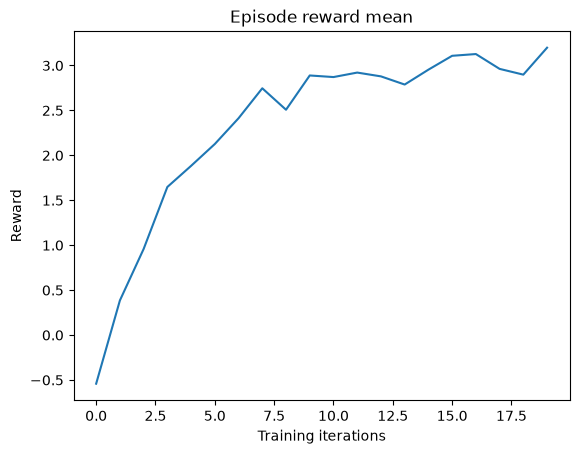

In [36]:
plt.plot(episode_reward_mean_list)
plt.xlabel("Training iterations")
plt.ylabel("Reward")
plt.title("Episode reward mean")
plt.show()

## Render

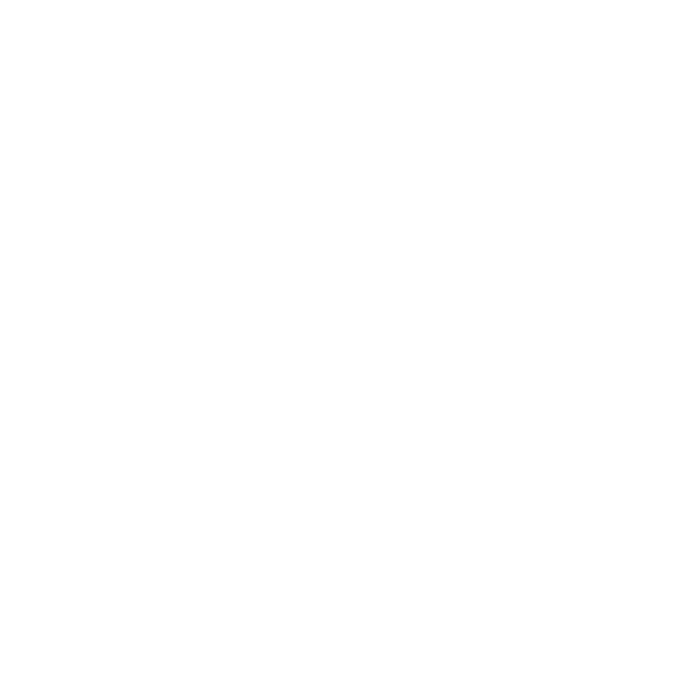

In [37]:
# import pyvirtualdisplay
# display = pyvirtualdisplay.Display(visible=False, size=(1400, 900))
# display.start()
# from PIL import Image

# def rendering_callback(env, td):
#     env.frames.append(Image.fromarray(env.render(mode="rgb_array")))
# env.frames = []
# with torch.no_grad():
#    env.rollout(
#        max_steps=max_steps,
#        policy=policy,
#        callback=rendering_callback,
#        auto_cast_to_device=True,
#        break_when_any_done=False,
#    )
# env.frames[0].save(
#     f"{scenario_name}.gif",
#     save_all=True,
#     append_images=env.frames[1:],
#    duration=3,
#    loop=0,
# )

# from IPython.display import Image
# Image(open(f"{scenario_name}.gif", "rb").read())
from PIL import Image as PILImage
from IPython.display import Image as NotebookImage, display

def rendering_callback(env, td):
    frame = env.render(
        mode="rgb_array",
        visualize_when_rgb=False,
    )
    env.frames.append(PILImage.fromarray(frame))

env.frames = []

with torch.no_grad():
    env.rollout(
        max_steps=max_steps,
        policy=policy,
        callback=rendering_callback,
        auto_cast_to_device=True,
        break_when_any_done=False,
    )

gif_path = f"maddpg_{scenario_name}.gif"

env.frames[0].save(
    gif_path,
    save_all=True,
    append_images=env.frames[1:],
    duration=30,
    loop=0,
)

display(NotebookImage(filename=gif_path))

# Questions and Answers

## Output-based validation of the saved run

The environment specification check completed successfully and the notebook contains no exception output. Both rendering cells produced valid 99-frame GIFs.

| Algorithm | Training iterations | Environment frames | Runtime | Final mean episode reward |
|---|---:|---:|---:|---:|
| MADDPG | 500 | 3,000,000 | 17:47 | 2.63 |
| MAPPO | 20 | 120,000 | 1:50 | 3.198 |

The MADDPG curve initially falls to a large negative reward, then recovers with noticeable oscillations before converging to a positive reward. MAPPO rises quickly and comparatively smoothly. Therefore, in this particular run, MAPPO converged faster, more stably, and with fewer environment interactions.

### 1. Why does MAPPO typically converge faster and more stably than MADDPG, while MADDPG often shows slow or unstable improvement in early training?

MAPPO combines stochastic exploration, GAE, repeated minibatch updates, and PPO's clipped probability-ratio objective. The clipping limits how far the policy can move on one batch, while the centralized critic supplies a lower-variance baseline that accounts for the other agents. MADDPG instead bootstraps a centralized joint-action $Q$-function and lets a deterministic actor follow its gradient. Early in training that critic is inaccurate, the joint observation-action input is high-dimensional, exploration depends on external action noise, and an actor can exploit critic errors before the target networks have stabilized. These effects make its early learning curve slower and more sensitive, although this is an empirical tendency rather than a universal guarantee.

This explanation is supported by the saved outputs: MAPPO reached a mean reward of 3.198 after 120,000 environment frames, whereas MADDPG reached 2.63 after 3,000,000 frames and showed a large early reward collapse.

### 2. Why is MADDPG generally more sample efficient than MAPPO?

MADDPG is off-policy: transitions can be stored in a replay buffer and reused in many later gradient updates, including after the behavior policy has changed. MAPPO is on-policy and may reuse the current rollout for only a bounded number of PPO epochs; after the policy changes substantially, old samples are no longer suitable for an ordinary on-policy policy-gradient estimate. Thus, MADDPG has greater *potential for sample reuse* per collected transition, even though its updates can be less stable.

This theoretical property is not demonstrated by the present run. Here, MAPPO obtained a higher reward with substantially fewer environment interactions. A defensible empirical comparison of sample efficiency would require equal environment-frame budgets, multiple random seeds, and uncertainty intervals.

### 3. What failure modes emerge in MAPPO if the critic becomes fully decentralized while the policy remains stochastic and shared across agents?

A local critic cannot condition on the other agents' observations or actions, so under partial observability it may be unable to explain a joint reward. It is not necessarily theoretically biased, because it can still represent an expected return conditioned on local information, but that information limitation creates irreducible uncertainty and generally higher-variance advantage estimates. Function approximation, bootstrapping, and changing teammate behavior can introduce additional estimation bias and non-stationarity.

Because the stochastic policy is shared, noisy or conflicting advantages from different agents are accumulated into the same parameters. This can produce destructive gradient interference, oscillation, poor credit assignment, symmetry or role collapse, and premature clipping of otherwise useful PPO updates. This decentralized-critic variant is IPPO and can still work when local observations are sufficiently informative or the task nearly factorizes, but it loses MAPPO's main centralized-training variance reduction.

### 4. What is the difference between IDDPG vs. MADDPG and IPPO vs. MAPPO?

| Algorithm | Actor during execution | Critic during training | Data regime |
|---|---|---|---|
| **IDDPG** | Deterministic, local observation | Decentralized: local observation and local action | Off-policy replay |
| **MADDPG** | Deterministic, local observation | Centralized: joint/global observations and actions | Off-policy replay |
| **IPPO** | Stochastic, local observation | Decentralized: local observation | On-policy PPO |
| **MAPPO** | Stochastic, local observation | Centralized: joint/global observations | On-policy PPO |

Thus, MADDPG and MAPPO follow centralized training with decentralized execution (CTDE), whereas IDDPG and IPPO decentralize the critic as well. Whether network parameters are shared among homogeneous agents is a separate design choice from critic centralization.

## Compatibility notes

- The dependency cell is now cross-platform: Linux-only `apt-get` and Xvfb setup is skipped on Windows and macOS.
- Both collectors explicitly enable automatic policy-transform registration for forward compatibility with newer TorchRL versions.
- The saved TensorDict `FutureWarning` is a version-compatibility notice and did not affect the completed training results.
